<a href="https://colab.research.google.com/github/etimush/MemoryNCA/blob/main/GeneCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EngramNCA**

In [29]:
#@title Get Packages and Images  { vertical-output: true}
%pip install git+https://github.com/etimush/MemoryNCA
#git clone --depth 1 --filter=blob:none --sparse https://github.com/etimush/MemoryNCA.git
%cd MemoryNCA && git sparse-checkout set Images
%mkdir Images && mv MemoryNCA/Images/* Images && rm -rf MemoryNCA

  Cloning https://github.com/etimush/MemoryNCA to c:\users\kurwinox\appdata\local\temp\pip-req-build-i484e44w
  Resolved https://github.com/etimush/MemoryNCA to commit 67ce16ed9323382b8e18a659dbf30140994a0333
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Note: you may need to restart the kernel to use updated packages.
[WinError 2] The system cannot find the file specified: 'MemoryNCA && git sparse-checkout set Images'
c:\Users\kurwinox\Documents\GitHub\EngramNCA


  Running command git clone --filter=blob:none --quiet https://github.com/etimush/MemoryNCA 'C:\Users\kurwinox\AppData\Local\Temp\pip-req-build-i484e44w'
  on a case-insensitive filesystem) and only one from the same
  colliding group is in the working tree:

    'docs/figures/Gene.drawio.svg'
    'docs/figures/gene.drawio.svg'

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
A subdirectory or file Images already exists.


In [2]:
import torch
print("CUDA Available:", torch.cuda.is_available())

CUDA Available: True


In [3]:
#@title Imports { vertical-output: true}
import random
import numpy as np
import matplotlib.pyplot as plt
from NCA.NCA import *
import NCA.utils as utils
from IPython.display import Image, HTML, clear_output
import logging
import os
from IPython.display import display, HTML, Video
from PIL import Image
import cv2
from base64 import b64encode
logger = logging.getLogger()
old_level = logger.level
logger.setLevel(100)

In [4]:
#@title Setup { vertical-output: true}
DEVICE = "cuda:0" #<-- Device to use, CUDA recommended
HEIGHT = 30 #@param {type:"integer"}
WIDTH = 30 #@param {type:"integer"}
CHANNELS = 16 # @param {type:"integer"}<--- NCA feature channels
BATCH_SIZE = 12 #@param {type:"integer"}
PADDING = 5 #@param {type:"integer"}
GENE_COUNT = 8 #@param {type:"integer"} <-- Number of gene channels to use for "private" information
POOL_SIZE = 2666 #@param {type:"integer"}<--- NCA training pool size, lower values train faster but are less stable
TRAINING_ITERS = 4000  #@param {type:"integer"}<-- Number of trainign iterations
HIDDEN_SIZE = 64 #@param {type:"integer"}<--- NCA hidden size
PRIMITIVES_SHAPES = ["Images/square.png", "Images/circle.png", "Images/triangle.png"]
PRIMITIVES_BODY_PARTS = ["Images/Torso.png", "Images/Head.png", "Images/Tail.png", "Images/leg1.png", "Images/leg2.png", "Images/leg3.png", "Images/leg4.png"]
PRIMITIVES_LINES = ["Images/horizontal.png", "Images/Verical.png"]
style = """
<style>
.output_wrapper, .output {
    display: flex;
    flex-direction: row-reverse; /* Align content to the right */
}
</style>
"""


In [5]:
#@title Load Primitives { vertical-output: true}

paths = PRIMITIVES_SHAPES #@param {type:"string"}
images = []
images_to_display = []
for path in paths:
    image, image_to_display = utils.get_image(path, HEIGHT, WIDTH, padding=PADDING)
    images.append(image)
    images_to_display.append(image_to_display)

genes = [[0], [2], [1]] # <-- Gene one hot encoding, indicates which bits if the gene sequence for each encoded "image" should be 1, [0] = 001, [0,1] = 011, [2] = 100 etc. for 3 bits genes. One, one-hot encoding per image, this rule applies for any gene size

HEIGHT = HEIGHT + 2*PADDING
WIDTH = WIDTH + 2*PADDING
assert len(paths) == len(genes), 'Genes and images should have the same length '

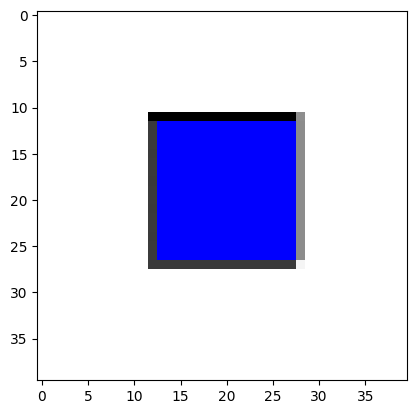

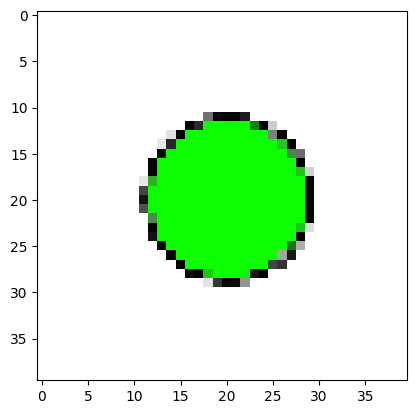

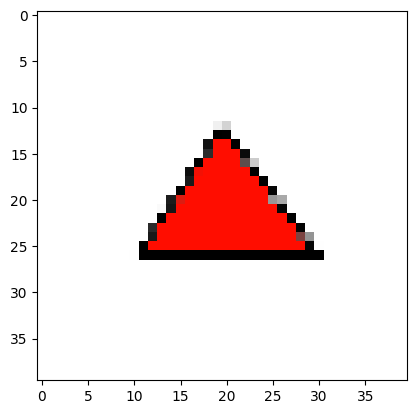

In [6]:
#@title Display Primitives { vertical-output: true}
for i,image in enumerate(images_to_display):
    plt.figure(3+i)
    plt.imshow(image)
pools = []
for gene in genes:
    pools.append(utils.make_gene_pool(gene, pool_size=POOL_SIZE,height=HEIGHT, width=WIDTH, channels=CHANNELS, gene_size=8))
seeds = []
for pool in pools:
    seeds.append(pool[0].clone())

In [7]:
#@title Get Batch Image Partitions { vertical-output: true}
partitions = len(paths)
if partitions == 1:
    part = [BATCH_SIZE]
div = BATCH_SIZE//partitions
rem = BATCH_SIZE % partitions
part = [div + 1 if i < rem else div for i in range(partitions)]
print(f"Batch image paritions = {part}. Batch Size of {BATCH_SIZE}. Number of Partitions = {partitions}")

Batch image paritions = [4, 4, 4]. Batch Size of 12. Number of Partitions = 3


In [8]:
#@title Load Filters for Loss Function { vertical-output: true}
sobel_x = torch.tensor([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]], dtype=torch.float32, device="cuda:0")
lap = torch.tensor([[1.0, 2.0, 1.0], [2.0, -12, 2.0], [1.0, 2.0, 1.0]], dtype=torch.float32, device="cuda:0")
filters = torch.stack([sobel_x, sobel_x.T, lap])
folder = "Gene"

In [9]:
#@title Create Path for Saving Models { vertical-output: true}
path = "Trained_models_base/" + folder
if not os.path.exists(path):
    os.makedirs(path)
    print(f"Path: {path} created")
else:
    print(f"Path: {path} already exists, all OK!")


Path: Trained_models_base/Gene already exists, all OK!


In [17]:
#@title Initialise NCA { vertical-output: true}
bases = [images[i].tile(part[i],1,1,1) for i in range(len(part))]
base = torch.cat(bases, dim =0 )
loss_log = []
nca = GeneCA(CHANNELS,HIDDEN_SIZE, gene_size=GENE_COUNT)
nca = nca.to(DEVICE)
optim = torch.optim.AdamW(nca.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optim, step_size=2000, gamma=0.3)
name = folder + "/" +type(nca).__name__ + "_gene_size_" +str(GENE_COUNT)

Batch


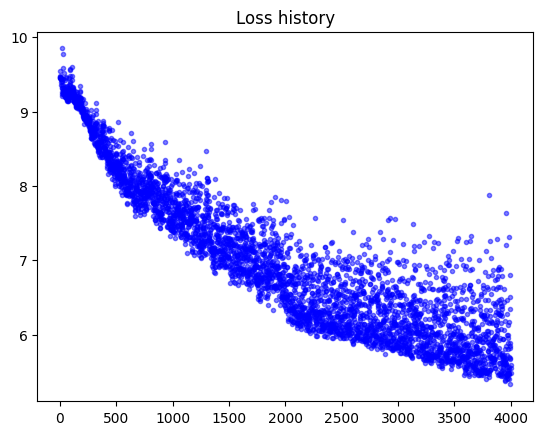

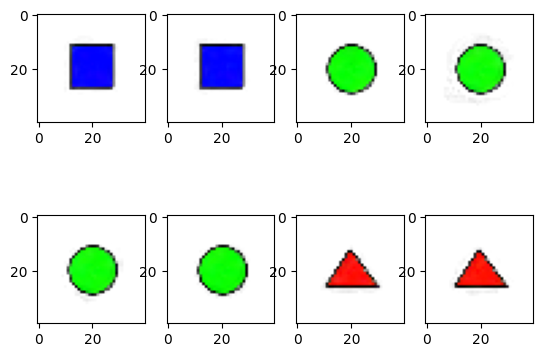

Trained_models_base/Gene/GeneCA_gene_size_8.pth


In [39]:
#@title Training { vertical-output: true}
for i in range(TRAINING_ITERS + 1):
    loss = 0
    with torch.no_grad():
        idxs, x = utils.get_gene_pool(pools, part, seeds)

    for _ in range( random.randrange(32,92)):
        x = nca(x)
    loss = (base - x[:, :4, :, :]).pow(2).sum() + 0.1 *(perchannel_conv(base, filters) - perchannel_conv(x[:, :4, :, :], filters) ).pow(2).sum()
    with torch.no_grad():
        loss.backward()
        for p in nca.parameters():
            p.grad /= (p.grad.norm() + 1e-8)
        optim.step()

        x = x.detach()
        optim.zero_grad()

    loss_log.append(loss.log().item())
    with torch.no_grad():
        pools = utils.udate_gene_pool(pools, x.clone().detach(), idxs, part)
    scheduler.step()

    if i % 100 == 0:
        print(f"Training itter {i}, loss = {loss.item()}")
        plt.clf()
        clear_output()
        plt.figure(1,figsize=(10, 4))
        plt.title('Loss history')
        plt.plot(loss_log, '.', alpha=0.5, color = "b")
        print("Batch")
        utils.show_batch(x[2:10])
        display(HTML(style))
        plt.show(block=False)
        plt.pause(0.01)
    if i % 100 == 0:
        torch.save(nca.state_dict(), "Trained_models_base/" + name + ".pth")
        print("Trained_models_base/" + name + ".pth")



In [15]:
#@title Video Utils { vertical-output: true}
path_video = "Saved_frames/GeneCA"

if not os.path.exists(path_video):
    os.makedirs(path_video)
    print(f"Path: {path_video} created")
else:
    print(f"Path: {path_video} already exists, all OK!")


def place_seed(x, center_x, center_y, seeds, seed_index):
    x[:,3:-8,center_x,center_y] = 1
    x[:,-3:,center_x,center_y] = seeds[seed_index]
    return x

def write_frame(x, path, frame_number, height, width, chn):
    image_np = x.clone().detach().cpu().permute(0,3,2,1).numpy().clip(0,1)[0,:,:,:3]


    plt.imsave(f"{path}/frame_{frame_number}.png", image_np)

def make_video(path, total_frames, height, width):
    fourcc = cv2.VideoWriter_fourcc(*'VP80')
    out = cv2.VideoWriter(path+'/output_video.mp4', fourcc, 30.0, (width, height))
    for frame_number in range(total_frames):
       frame_path = path+f"/frame_{frame_number}.png"
       frame = cv2.imread(frame_path)
       #frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

       out.write(frame)
    out.release()

Path: Saved_frames/GeneCA already exists, all OK!


In [41]:
#@title Create Video { vertical-output: true}
del nca
del optim
torch.cuda.empty_cache()
seeds = [torch.tensor([0.0,0.0,1.0], device=DEVICE),torch.tensor([1.0,0.0,0.0], device=DEVICE),torch.tensor([0.0,1.0,0.0], device=0),torch.tensor([1.0,0.0,1.0], device=DEVICE)]
seed_locs = [[10, 10], [40,40], [80,80], [120,120]]
seed_index = 0

nca = GeneCA(CHANNELS,hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT)
nca.load_state_dict(torch.load("Trained_models_base/Gene/GeneCA_gene_size_8.pth"))
nca.to(DEVICE).eval()
x_prime = torch.zeros((1,CHANNELS, HEIGHT*4, WIDTH*4), dtype=torch.float32).cuda()
frame_count = 499
for i in range(frame_count):
    x_prime = nca(x_prime)
    if i % 50 == 0:
        place_seed(x_prime, seed_locs[seed_index][0], seed_locs[seed_index][1], seeds, seed_index)
        seed_index = (seed_index + 1) % len(seeds)
    x_prime = x_prime.detach()
    write_frame(x_prime, path_video, i, HEIGHT*4, WIDTH*4,CHANNELS)
make_video(path_video, frame_count, HEIGHT*4, WIDTH*4)


In [42]:
#@title Display Vide { vertical-output: true}
Video(path_video+'/output_video.mp4', embed=True, width=320, height=320)

# **Gene Propogatio CA**

In [18]:
#@title Setup { vertical-output: true}
del nca
torch.cuda.empty_cache()
HEIGHT = 60 #@param {type:"integer"}
WIDTH = 60 #@param {type:"integer"}
BATCH_SIZE = 10 #@param {type:"integer"}
LIZARD = [ "Images/lizard.png"]
BUTTERFLY = [ "Images/BUTTERFLY.png"]
SPIDER = [ "Images/spider.png"]
MULTIPLE = [] #<-- add multiple path for training multiple NCA morphologies into one
TRAINING_ITERS = 14000 #@param {type:"integer"}
HIDDEN_SIZE_PROP = 124 #@param {type:"integer"}
PADDING = 0 #@param {type:"integer"}


In [44]:
#@title Load Image { vertical-output: true}
paths = LIZARD #@param {type:"string"}
images = []
images_to_display = []
for path in paths:
    image, image_to_display = utils.get_image(path, HEIGHT, WIDTH, padding=PADDING)
    images.append(image)
    images_to_display.append(image_to_display)
genes = [[1]]
HEIGHT = HEIGHT + 2*PADDING
WIDTH = WIDTH + 2*PADDING
assert len(paths) == len(genes), 'Genes and images should have the same length '

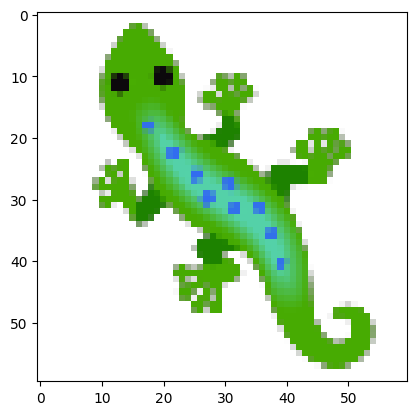

In [45]:
#@title Display Image { vertical-output: true}
for i,image in enumerate(images_to_display):
    plt.figure(3+i)
    plt.imshow(image)
pools = []
for gene in genes:
    pools.append(utils.make_gene_pool(gene, pool_size= 1000, height=HEIGHT, width=WIDTH, channels=CHANNELS, gene_size=8))
seeds = []
for pool in pools:
    seeds.append(pool[0].clone())

In [46]:
#@title Get Batch Image Partition { vertical-output: true}
partitions = len(paths)
if partitions == 1:
    part = [BATCH_SIZE]
div = BATCH_SIZE//partitions
rem = BATCH_SIZE % partitions
part = [div + 1 if i < rem else div for i in range(partitions)]
print(f"Batch image paritions = {part}. Batch Size of {BATCH_SIZE}. Number of Partitions = {partitions}")

Batch image paritions = [10]. Batch Size of 10. Number of Partitions = 1


In [47]:
#@title Generate Extra Genes for Multi Morphology GeneProp CA { vertical-output: true}
gene_2 = []
for idx,p in enumerate(part):
    gene = torch.zeros((1,HEIGHT,WIDTH), device=DEVICE)
    gene[:,HEIGHT//2,WIDTH//2] = idx
    gene_2.append(gene.tile(p, 1, 1, 1))
genes = torch.cat(gene_2, dim = 0)

In [48]:
#@title Create Path for Saving Models { vertical-output: true}
folder = "GeneProp"
path = "Trained_models_base/" + folder
if not os.path.exists(path):
    os.makedirs(path)
    print(f"Path: {path} created")
else:
    print(f"Path: {path} already exists, all OK!")

Path: Trained_models_base/GeneProp created


In [49]:
#@title Initialise GeneCA (static) and GeneProp CA for Trainign { vertical-output: true}
bases = [images[i].tile(part[i],1,1,1) for i in range(len(part))]
base = torch.cat(bases, dim =0 )
loss_log = []
with torch.no_grad():
    ncaPre = GeneCA(CHANNELS,hidden_n=64, gene_size=GENE_COUNT)
    ncaPre.load_state_dict(torch.load("Trained_models_base/Gene/GeneCA_gene_size_8.pth"))
    ncaPre.to(DEVICE).eval()
nca = GenePropCA(CHANNELS,HIDDEN_SIZE_PROP, gene_size=GENE_COUNT)
nca = nca.to(DEVICE)
optim = torch.optim.AdamW(nca.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optim, step_size=5000, gamma=0.3)
name = folder + "/" +type(nca).__name__ + "_gene_size_" +str(GENE_COUNT)

GeneProp/GenePropCA_gene_size_8


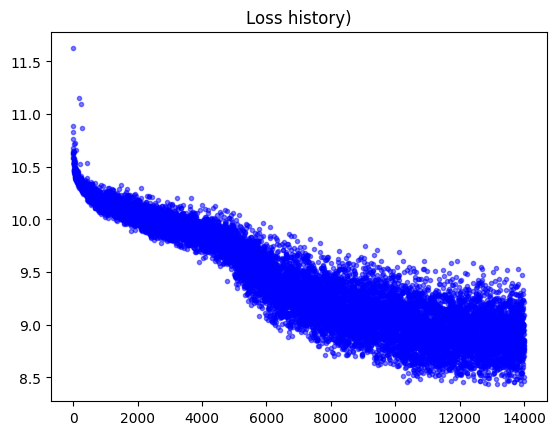

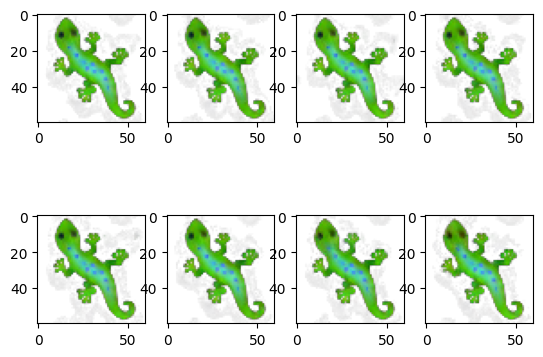

In [50]:
#@title Train GeneProp CA { vertical-output: true}
#TODO: Make it so that multi image gene props use the secondary genes
for i in range(TRAINING_ITERS + 1):
    loss = 0
    with torch.no_grad():
        idxs, x = utils.get_gene_pool(pools, part, seeds)

    itters = random.randrange(32,92)
    for _ in range( itters):
        x = ncaPre(x)
        x = nca(x)

    loss = (base - x[:, :4, :, :]).pow(2).sum() + 0.1 *(perchannel_conv(base, filters) - perchannel_conv(x[:, :4, :, :], filters) ).pow(2).sum()
    with torch.no_grad():
        loss.backward()
        for p in nca.parameters():
            p.grad /= (p.grad.norm() + 1e-8)
        optim.step()
        x = x.detach()
        optim.zero_grad()

    loss_log.append(loss.log().item())
    with torch.no_grad():
        pools = utils.udate_gene_pool(pools, x.clone().detach(), idxs, part)
    scheduler.step()

    if i % 100 == 0:
        print(f"Training itter {i}, loss = {loss.item()}")
        plt.clf()
        clear_output()
        plt.figure(1,figsize=(10, 4))
        plt.title('Loss history)')
        print(name)
        plt.plot(loss_log, '.', alpha=0.5, color = "b")
        utils.show_batch(x[2:10])
        plt.show(block=False)
        plt.pause(0.01)
    if i % 100 == 0:
        torch.save(nca.state_dict(), "Trained_models_base/" + name + ".pth")

In [51]:
#@title Create Video { vertical-output: true}
del nca
del ncaPre
del optim
torch.cuda.empty_cache()
path_video = "Saved_frames/GenePropCA"
if not os.path.exists(path_video):
    os.makedirs(path_video)
    print(f"Path: {path_video} created")
else:
    print(f"Path: {path_video} already exists, all OK!")
seeds = [torch.tensor([0.0,1.0,0.0], device=DEVICE)]
seed_locs = [[30,30]]
seed_index = 0

nca = GeneCA(CHANNELS,hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT)
nca.load_state_dict(torch.load("Trained_models_base/Gene/GeneCA_gene_size_8.pth"))
nca.to(DEVICE).eval()
nca_prop = GenePropCA(CHANNELS,hidden_n=HIDDEN_SIZE_PROP, gene_size=GENE_COUNT)
nca_prop.load_state_dict(torch.load("Trained_models_base/GeneProp/GenePropCA_gene_size_8.pth"))
nca_prop.to(DEVICE).eval()
x_prime = torch.zeros((1,CHANNELS, HEIGHT, WIDTH), dtype=torch.float32).cuda()
place_seed(x_prime, seed_locs[seed_index][0], seed_locs[seed_index][1], seeds, seed_index)
frame_count = 500
for i in range(frame_count):
    x_prime = nca(x_prime)
    x_prime = x_prime.detach()
    if i > 50:
        x_prime = nca_prop(x_prime)
    write_frame(x_prime, path_video, i, HEIGHT, WIDTH,CHANNELS)
make_video(path_video, frame_count, HEIGHT, WIDTH)

Path: Saved_frames/GenePropCA already exists, all OK!


In [52]:
#@title Display Vide { vertical-output: true}
Video(path_video+'/output_video.mp4', embed=True, width=320, height=320)

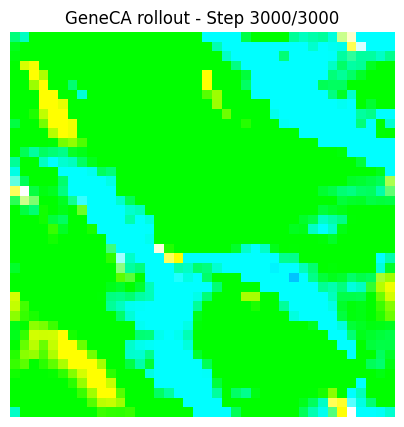

In [ ]:
#@title Inspect GeneCA one sample
from pathlib import Path
from IPython.display import display

INSPECT_STEPS = 3000 
INSPECT_SEED = [1] 
if not torch.cuda.is_available():
    raise RuntimeError("Inspection requires CUDA because the NCA kernels use CUDA tensors.")
INSPECT_DEVICE = torch.device(DEVICE)

def _load_checkpoint(model, checkpoint):
    checkpoint_path = Path(checkpoint)
    if not checkpoint_path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")
    model.load_state_dict(torch.load(checkpoint_path, map_location=INSPECT_DEVICE))
    return model.to(INSPECT_DEVICE).eval()

def _make_inspection_seed(gene, height, width):
    return utils.make_gene_pool(gene, pool_size=1, height=height, width=width,
                                channels=CHANNELS, device=str(INSPECT_DEVICE),
                                gene_size=GENE_COUNT)

def _state_to_image(state):
    return state[0, :3].detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()

def _show_snapshots(snapshots, title):
    columns = min(4, len(snapshots))
    rows = (len(snapshots) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, squeeze=False, figsize=(3 * columns, 3 * rows))
    for ax, (step, image) in zip(axes.flat, snapshots):
        ax.imshow(image)
        ax.set_title(f"Step {step}")
        ax.axis("off")
    for ax in axes.flat[len(snapshots):]:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def _rollout(step_fn, steps, snapshot_every, title, video_path):
    snapshots, frames = [], []
    with torch.no_grad():
        for step in range(steps + 1):
            image = _state_to_image(x_inspect)
            frames.append((image * 255).astype(np.uint8))
            if step == 0 or step % snapshot_every == 0 or step == steps:
                snapshots.append((step, image))
            if step < steps:
                x_inspect.copy_(step_fn(x_inspect))
    _show_snapshots(snapshots, title)
    video_path = Path(video_path)
    video_path.parent.mkdir(parents=True, exist_ok=True)
    height, width = frames[0].shape[:2]
    writer = cv2.VideoWriter(str(video_path), cv2.VideoWriter_fourcc(*"mp4v"), 10.0, (width, height))
    if not writer.isOpened():
        raise RuntimeError(f"Could not open video writer: {video_path}")
    for frame in frames:
        writer.write(cv2.cvtColor(frame, cv2.COLOR_RGB2BGR))
    writer.release()
    display(Video(str(video_path), embed=True, width=320, height=320))
    return snapshots, video_path

def _watch_rollout(step_fn, steps, title):
    fig, ax = plt.subplots(figsize=(5, 5))
    image_artist = None
    display_handle = display(fig, display_id=True)
    with torch.no_grad():
        for step in range(steps):
            image = _state_to_image(x_inspect)
            if image_artist is None:
                image_artist = ax.imshow(image)
                ax.axis("off")
            else:
                image_artist.set_data(image)
            ax.set_title(f"{title} - Step {step + 1}/{steps}")
            display_handle.update(fig)
            x_inspect.copy_(step_fn(x_inspect))
    plt.close(fig)

gene_model = _load_checkpoint(GeneCA(CHANNELS, hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT),
                              f"Trained_models/Gene/GeneCA_gene_size_{GENE_COUNT}.pth")
x_inspect = _make_inspection_seed(INSPECT_SEED, HEIGHT, WIDTH)
_watch_rollout(lambda state: gene_model(state), INSPECT_STEPS, "GeneCA rollout")

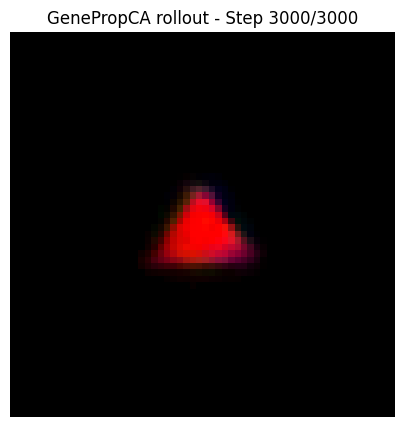

In [19]:
#@title Inspect GeneProgatioCA one sample 
PROP_INSPECT_STEPS = 3000 
PROP_WARMUP_STEPS = 50 
PROP_INSPECT_SEED = [1] 
prop_base_model = _load_checkpoint(GeneCA(CHANNELS, hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT),
                                   f"Trained_models/Gene/GeneCA_gene_size_{GENE_COUNT}.pth")
prop_model = _load_checkpoint(GenePropCA(CHANNELS, hidden_n=HIDDEN_SIZE_PROP, gene_size=GENE_COUNT),
                              f"Trained_models/GeneProp/GenePropCA_gene_size_{GENE_COUNT}.pth")
x_inspect = _make_inspection_seed(PROP_INSPECT_SEED, HEIGHT, WIDTH)
with torch.no_grad():
    for _ in range(PROP_WARMUP_STEPS):
        x_inspect.copy_(prop_base_model(x_inspect))
_watch_rollout(lambda state: prop_model(state), PROP_INSPECT_STEPS, "GenePropCA rollout")

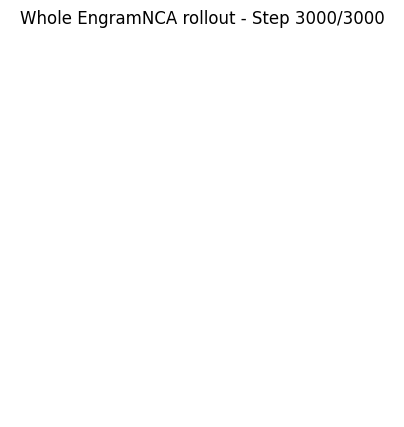

In [21]:
#@title Inspect whole EngramNCA one sample 
ENGRAM_INSPECT_STEPS = 3000 
ENGRAM_INSPECT_SEED = [1] 
engram_gene_model = _load_checkpoint(GeneCA(CHANNELS, hidden_n=HIDDEN_SIZE, gene_size=GENE_COUNT),
                              f"Trained_models/Gene/GeneCA_gene_size_{GENE_COUNT}.pth")
engram_prop_model = _load_checkpoint(GenePropCA(CHANNELS, hidden_n=HIDDEN_SIZE_PROP, gene_size=GENE_COUNT),
                                     f"Trained_models/GeneProp/GenePropCA_gene_size_{GENE_COUNT}.pth")
x_inspect = _make_inspection_seed(ENGRAM_INSPECT_SEED, HEIGHT, WIDTH)
engram_switch_step = 50
def _engram_step(state):
    state = engram_gene_model(state)
    if _engram_step.step >= engram_switch_step:
        state = engram_prop_model(state)
    _engram_step.step += 1
    return state
_engram_step.step = 0
_watch_rollout(_engram_step, ENGRAM_INSPECT_STEPS, "Whole EngramNCA rollout")